In [2]:
import requests
import pandas as pd
from bs4 import BeautifulSoup
from shapely.geometry import Point
import geopandas
import matplotlib.pyplot as plt
import json
import re

In [3]:
cla = 'https://cla.berkeley.edu/browse/language-list.html'

In [4]:
html_content = requests.get(cla).content

soup = BeautifulSoup(html_content, 'html.parser')

In [5]:
language_links = soup.select('div.group a')

In [6]:
language_names = [link.text.strip() for link in language_links]

In [7]:
language_names = [name for name in language_names if name.strip()]

In [116]:
language_names

["A'ewa",
 "A'ingae",
 'Abaza',
 'Abenaki',
 'Abenaqui',
 'Abo',
 'Achomawi',
 'Achumawi',
 'Acjachemem',
 'Acoma',
 'Adyghe',
 'Aewa',
 'Agni',
 'Aguaruna',
 'Agwara Kambari',
 'Aht',
 'Ahtena',
 'Ahtna',
 'Aikanã',
 "Akimel O'odham",
 "Akwa'ala",
 'Alabama',
 'Aleut',
 'Algic',
 'Algonkin',
 'Algonquian',
 'Algonquin',
 'Alsea',
 'Alsea',
 'Alutiiq',
 'Amahuaca',
 'Amarakaeri',
 'Andoa',
 'Anglo-Frisian',
 'Angloromani',
 'Apache',
 'Applegate',
 'Apsaloka',
 'Apsaroka',
 'Arabela',
 'Arabic',
 'Arakbut',
 'Arakmbut',
 'Arapaho',
 'Arapaho',
 'Arikara',
 'Ashaninka',
 'Ashochimi',
 'Assiniboine',
 'Atakapa',
 'Atchan',
 'Athabascan',
 'Athabaskan',
 'Athapascan',
 'Athapaskan',
 'Atna',
 'Atorad',
 'Atorai',
 'Atsina',
 'Atsugewi',
 'Awajún',
 'Aymara',
 'Aztec',
 'Aztecan',
 'Aʔɨwa',
 'Bahtssal',
 'Bantu',
 'Barbareño',
 'Barese',
 'Basque',
 'Bear River Athabaskan',
 'Beaver',
 'Bella Bella',
 'Bella Coola',
 'Biloxi',
 'Bishnupriya Manipuri',
 'Blackfoot',
 'Bodega Miwok',
 'Bribr

In [8]:
len(language_names)

774

In [9]:
glottolog_data = pd.read_csv('languages_and_dialects_geo.csv')

In [10]:
glottolog_data

,glottocode,name,isocodes,level,macroarea,latitude,longitude
0,3adt1234,3Ad-Tekles,NaN,dialect,Africa,NaN,NaN
1,aala1237,Aalawa,NaN,dialect,Papunesia,NaN,NaN
2,aant1238,Aantantara,NaN,dialect,Papunesia,NaN,NaN
3,aari1239,Aari,aiw,language,Africa,5.95034,36.5721
4,aari1240,Aariya,aay,language,Eurasia,NaN,NaN
...,...,...,...,...,...,...,...
22106,zuwa1238,Zuwadza,NaN,dialect,Papunesia,NaN,NaN
22107,zwal1238,Zwall,NaN,dialect,Africa,NaN,NaN
22108,zyph1238,Zyphe,zyp,language,Eurasia,22.52400,93.2640
22109,zyud1238,Zyuzdin,NaN,dialect,Eurasia,NaN,NaN


In [11]:
df_filtered = glottolog_data[glottolog_data['name'].isin(language_names)]

In [12]:
df_filtered

,glottocode,name,isocodes,level,macroarea,latitude,longitude
28,abaz1241,Abaza,abq,language,Eurasia,44.250000,42.000000
51,aboo1242,Abo,NaN,dialect,Africa,NaN,NaN
94,achu1247,Achumawi,acv,language,North America,41.097900,-121.191000
159,abis1238,Aewa,ash,language,South America,-1.284096,-75.084405
224,agua1253,Aguaruna,agr,language,South America,-5.300440,-77.921800
...,...,...,...,...,...,...,...
21836,yoru1245,Yoruba,yor,language,Africa,7.153450,3.672250
21861,yuch1247,Yuchi,yuc,language,North America,35.750000,-86.750000
21881,yuki1244,Yuki,NaN,dialect,North America,NaN,NaN
21899,yuro1248,Yurok,yur,language,North America,41.326200,-123.824000


In [13]:
points = df_filtered.apply(lambda r: Point(r.longitude, r.latitude), axis=1)
gdb = geopandas.GeoDataFrame(df_filtered.assign(geometry=points), \
                        crs={'init' :'epsg:4326'})
xys = gdb['geometry'].apply(lambda pt: pd.Series({'x': pt.x, 'y': pt.y}))
gdb['x'] = xys['x']
gdb['y'] = xys['y']

/Users/go202/anaconda3/envs/eq_pap_1/lib/python3.12/site-packages/pyproj/crs/crs.py:141: FutureWarning: '+init=<authority>:<code>' syntax is deprecated. '<authority>:<code>' is the preferred initialization method. When making the change, be mindful of axis order changes: https://pyproj4.github.io/pyproj/stable/gotchas.html#axis-order-changes-in-proj-6
  in_crs_string = _prepare_from_proj_string(in_crs_string)


In [14]:
worldmap = geopandas.read_file(geopandas.datasets.get_path("naturalearth_lowres"))

/var/folders/hw/3z11r39j0gd4kgzxbjj6v8z80000gp/T/ipykernel_93487/867032107.py:1: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  worldmap = geopandas.read_file(geopandas.datasets.get_path("naturalearth_lowres"))


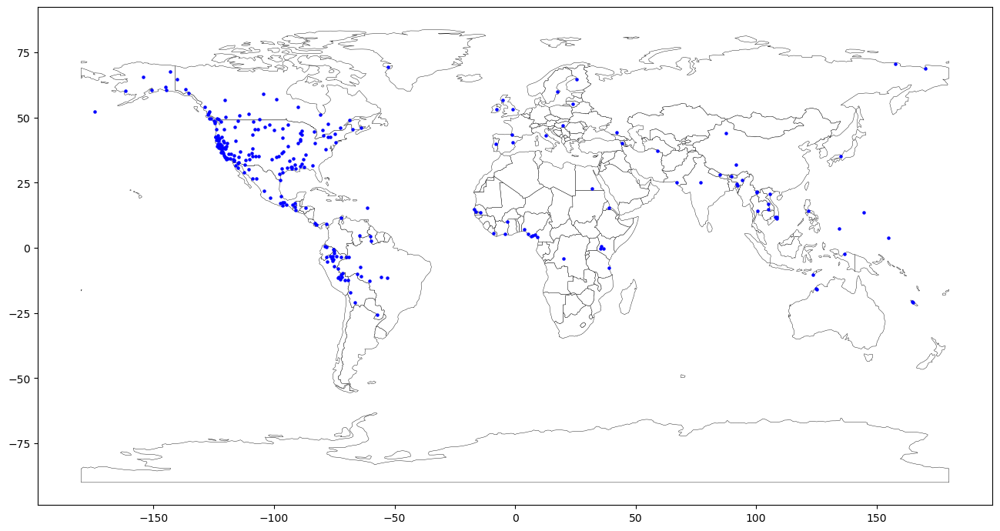

In [15]:
fig, ax = plt.subplots(figsize=(16, 10))
worldmap.plot(color="white", edgecolor = 'black',ax=ax, linewidth=0.3)
gdb.plot(ax=ax, color = 'blue', markersize = 5)
plt.show()

In [16]:
items = 'https://cla.berkeley.edu/list/index.html?size=25&collfrom=0&bndlfrom=0&collpage=0&bndlpage=0&tab=bndl&with_js=1'

In [17]:
url = 'https://xfhpwly456.execute-api.us-east-1.amazonaws.com/api/sq'
headers = {
    'User-Agent': 'Mozilla/5.0 (Macintosh; Intel Mac OS X 10.15; rv:124.0) Gecko/20100101 Firefox/124.0',
    'Accept': 'application/json, text/javascript, */*; q=0.01',
    'Accept-Language': 'en-GB,en;q=0.5',
    'Accept-Encoding': 'gzip, deflate, br',
    'Content-Type': 'application/x-www-form-urlencoded; charset=UTF-8',
    'Origin': 'https://cla.berkeley.edu',
    'DNT': '1',
    'Sec-GPC': '1',
    'Connection': 'keep-alive',
    'Referer': 'https://cla.berkeley.edu/',
    'Sec-Fetch-Dest': 'empty',
    'Sec-Fetch-Mode': 'cors',
    'Sec-Fetch-Site': 'cross-site',
    'TE': 'trailers'
}

data = {
    "qstr": [],
    "tab": "bndl",
    "with_js": "1",
    "size": "25",
    "bndlfrom": "0"
}

# Iterate over different values of bndlfrom
for i in range(1, 5001, 500):
    data['bndlfrom'] = str(i)
    response = requests.post(url, headers=headers, json=data)
    print(f"Request for bndlfrom={i} - Status code: {response.status_code}")

Request for bndlfrom=1 - Status code: 200
Request for bndlfrom=501 - Status code: 200
Request for bndlfrom=1001 - Status code: 200
Request for bndlfrom=1501 - Status code: 200
Request for bndlfrom=2001 - Status code: 200
Request for bndlfrom=2501 - Status code: 200
Request for bndlfrom=3001 - Status code: 200
Request for bndlfrom=3501 - Status code: 200
Request for bndlfrom=4001 - Status code: 200
Request for bndlfrom=4501 - Status code: 200


In [18]:
response.content

b'{"coll":{"took":7,"timed_out":false,"_shards":{"total":1,"successful":1,"skipped":0,"failed":0},"hits":{"total":500,"max_score":null,"hits":[{"_index":"cla1-coll","_type":"coll","_id":"11259","_score":null,"_source":{"bndlid":["29128","29129","29130","29131","29132","29133","29134","29135","29136","29137","29138","29139","29140","29141","29142","29143","29144","29145","29146","29147","29148","29149","29150","29151","29152","29153","29154","29155","29156","29157","29158","29159","29160","29161","29162","29163","29164","29165","29166","29167","29168","29169","29170","29171","29172","29173","29174","29175","29176","29177","29178","29179","29180","29181","29182","29183","29184","29185","29186","29187","29188","29189","29190","29191","29192","29193","29194","29195","29196","29199","29200","32894","32895","32896","32897","32919","36465","36466","36467","36468","36469","36470","36471","36472","36473","36474","36475","36476","36477","36478","36479","36480","36481","36482","36483","36484","36

In [109]:
len(response.content)

175101

In [115]:
len(data)

2

In [113]:
f = open('./CLA/cla.json')

In [114]:
data = json.load(f)

In [21]:
data

{'coll': {'took': 66,
  'timed_out': False,
  '_shards': {'total': 1, 'successful': 1, 'skipped': 0, 'failed': 0},
  'hits': {'total': 500,
   'max_score': None,
   'hits': [{'_index': 'cla1-coll',
     '_type': 'coll',
     '_id': '11259',
     '_score': None,
     '_source': {'bndlid': ['29128',
       '29129',
       '29130',
       '29131',
       '29132',
       '29133',
       '29134',
       '29135',
       '29136',
       '29137',
       '29138',
       '29139',
       '29140',
       '29141',
       '29142',
       '29143',
       '29144',
       '29145',
       '29146',
       '29147',
       '29148',
       '29149',
       '29150',
       '29151',
       '29152',
       '29153',
       '29154',
       '29155',
       '29156',
       '29157',
       '29158',
       '29159',
       '29160',
       '29161',
       '29162',
       '29163',
       '29164',
       '29165',
       '29166',
       '29167',
       '29168',
       '29169',
       '29170',
       '29171',
       '29172

In [22]:
bndl_data = data['bndl']


In [23]:
bndl_data

{'took': 50,
 'timed_out': False,
 '_shards': {'total': 1, 'successful': 1, 'skipped': 0, 'failed': 0},
 'hits': {'total': 22132,
  'max_score': None,
  'hits': [{'_index': 'cla1-bndl',
    '_type': 'bndl',
    '_id': '18996',
    '_score': None,
    '_source': {'has_audio': True,
     'datestr': '06 Jun 1985',
     'bndlid': '18996',
     'bndlident': 'LA163.035',
     'assetcnt': 2,
     'collident': 'LA163',
     'collid': '10007',
     'title': ' Elicitation of words and phrases',
     'ul_md': '<ul class="md">\n  <li><span class=\'label\'>Item identifier:</span>&nbsp;LA163.035</li>\n  <li><span class=\'label\'>Date:</span>&nbsp;06 Jun 1985</li><li><span class=\'label\'>Contributors:</span>&nbsp;<a href="/list/?pplid=305=Frances Jack" class="post">Frances Jack</a> (consultant); <a href="/list/?pplid=518=Marianne Mithun" class="post">Marianne Mithun</a> (researcher)</li><li><span class=\'label\'>Language:</span>&nbsp;<a href="/list/?langid=272=Central Pomo" class="post">Central Pomo

In [24]:
data = []
for item in bndl_data['hits']['hits']:
    sort = item['sort'][0]
    ul_md = item['_source']['ul_md']
    
    # Applying regex to extract language name
    language_match = re.search(r'<span class=\'label\'>Language:</span>&nbsp;<a .*?>(.*?)</a>', ul_md)
    if language_match:
        language = language_match.group(1)
    else:
        language = None
    
    data.append({'name': sort, 'language': language, 'ul_md': ul_md})

df = pd.DataFrame(data)
print(df)

                                                  name      language  \
0                     Elicitation of words and phrases  Central Pomo   
1    "Baula" or Dream Song predicting the Coming of...       Nomlaki   
2                                          "Frog" Song        Mojave   
3                                          "Frog" Song        Mojave   
4                                          "Frog" Song        Mojave   
..                                                 ...           ...   
995                                     Biting oneself     Nez Perce   
996  Black notebook: All notes from first half of f...         Limba   
997  Black wolf beats thunder in a race. Includes a...        Shasta   
998  Blackfoot historical phonology: A preliminary ...     Blackfoot   
999  Blake describes a hunter hunting a deer. Sente...      Atsugewi   

                                                 ul_md  
0    <ul class="md">\n  <li><span class='label'>Ite...  
1    <ul class="md">\

In [25]:
k = df['ul_md'].to_list()

In [26]:
k

['<ul class="md">\n  <li><span class=\'label\'>Item identifier:</span>&nbsp;LA163.035</li>\n  <li><span class=\'label\'>Date:</span>&nbsp;06 Jun 1985</li><li><span class=\'label\'>Contributors:</span>&nbsp;<a href="/list/?pplid=305=Frances Jack" class="post">Frances Jack</a> (consultant); <a href="/list/?pplid=518=Marianne Mithun" class="post">Marianne Mithun</a> (researcher)</li><li><span class=\'label\'>Language:</span>&nbsp;<a href="/list/?langid=272=Central Pomo" class="post">Central Pomo</a> (poo)</li><li><span class=\'label\'>Place:</span>&nbsp;<a href="/list/?placeid=212=Hopland, CA" class="post">Hopland, CA</a></li><li><span class=\'label\'>Description:</span>&nbsp;<span>No English glosses.</span></li><li><span class=\'label\'>Availability:</span>&nbsp;Restricted. (Access to Item number LA 163.035 requires depositor permission. Email <a href="mailto:scoil-ling@berkeley.edu">scoil-ling@berkeley.edu</a> to inquire.)</li><li><span class=\'label\'>Catalog history:</span>&nbsp;<span

In [32]:
def extract_file_info(ul_md):
    soup = BeautifulSoup(ul_md, 'html.parser')
    detailonly_element = soup.find('p', class_='detailonly')
    if detailonly_element:
        file_info_list = []
        size_info_list = []
        br_tags = detailonly_element.find_all('br')
        if br_tags:
            for br_tag in br_tags:
                next_sibling = br_tag.next_sibling
                if next_sibling is not None:
                    br_text = br_tag.next_sibling.strip()
                    match = re.match(r'(.+)\s+\((\d+)\s+bytes\)', br_text)
                    if match:
                        file_info = match.group(1)
                        size_info = match.group(2)
                        file_info_list.append(file_info)
                        size_info_list.append(size_info) 
        if file_info_list and size_info_list:
            return file_info_list, size_info_list
    return 'not found', 'not found'

In [28]:
tr = [extract_file_info(i) for i in k]

In [29]:
tr

[(['LA163.035.001.wav', 'LA163.035.002.wav'], ['294322306', '466784386']),
 ('not found', 'not found'),
 (['14-1138.txt', '14-1138.wav', '14-1138_filtered.wav'],
  ['8584', '11888730', '11888806']),
 (['14-1139.txt', '14-1139.wav', '14-1139_filtered.wav'],
  ['8291', '11212356', '11212432']),
 ('not found', 'not found'),
 (['14-1141.txt', '14-1141.wav', '14-1141_filtered.wav'],
  ['13455', '11679128', '11679204']),
 (['14-1142.wav', '14-1142_filtered.wav'], ['22955096', '22955096']),
 ('not found', 'not found'),
 (['14-1144.txt', '14-1144.wav', '14-1144_filtered.wav'],
  ['8335', '11676250', '11676326']),
 (['14-1145.txt', '14-1145.wav', '14-1145_filtered.wav'],
  ['8487', '11669210', '11669286']),
 (['14-1146.txt', '14-1146.wav', '14-1146_filtered.wav'],
  ['8487', '11663342', '11663418']),
 (['14-1147.txt', '14-1147.wav', '14-1147_filtered.wav'],
  ['8192', '10985690', '10985766']),
 (['14-1148.txt', '14-1148.wav', '14-1148_filtered.wav'],
  ['8161', '11247928', '11248004']),
 (['14-

In [52]:
data = []
for item in bndl_data['hits']['hits']:
    sort = item['sort'][0]
    ul_md = item['_source']['ul_md']
    
    # Extracting language name
    language_match = re.search(r'<span class=\'label\'>Language:</span>&nbsp;<a .*?>(.*?)</a>', ul_md)
    if language_match:
        language = language_match.group(1)
    else:
        language = None
    
    # Extracting file information
    file_info_list, size_info_list = extract_file_info(ul_md)
    print(file_info_list)
    
    # Creating data dictionary
    data_dict = {'name': sort, 'language': language, 'ul_md': ul_md}
    
    # If file information is available, add it to the dictionary
    if file_info_list and size_info_list:
        data_dict['file_info'] = file_info_list
        data_dict['file_size'] = size_info_list
    
    data.append(data_dict)

# Create DataFrame
df = pd.DataFrame(data)
print(df)


['LA163.035.001.wav', 'LA163.035.002.wav']
not found
['14-1138.txt', '14-1138.wav', '14-1138_filtered.wav']
['14-1139.txt', '14-1139.wav', '14-1139_filtered.wav']
not found
['14-1141.txt', '14-1141.wav', '14-1141_filtered.wav']
['14-1142.wav', '14-1142_filtered.wav']
not found
['14-1144.txt', '14-1144.wav', '14-1144_filtered.wav']
['14-1145.txt', '14-1145.wav', '14-1145_filtered.wav']
['14-1146.txt', '14-1146.wav', '14-1146_filtered.wav']
['14-1147.txt', '14-1147.wav', '14-1147_filtered.wav']
['14-1148.txt', '14-1148.wav', '14-1148_filtered.wav']
['14-1149.txt', '14-1149.wav', '14-1149_filtered.wav']
not found
not found
not found
['14-2369.wav', '14-2369_filtered.wav']
['14-1992.txt', '14-1992.wav', '14-1992_filtered.wav']
not found
not found
not found
['14-693.txt', '14-693a.wav', '14-693a_filtered.wav']
['14-693.txt', '14-693b.wav', '14-693b_filtered.wav']
['14-694.txt', '14-694.wav', '14-694_filtered.wav']
['14-737.txt', '14-737a.wav', '14-737a_filtered.wav']
['14-737.txt', '14-737b

In [53]:
df

,name,language,ul_md,file_info,file_size
0,Elicitation of words and phrases,Central Pomo,"<ul class=""md"">\n <li><span class='label'>Ite...","[LA163.035.001.wav, LA163.035.002.wav]","[294322306, 466784386]"
1,"""Baula"" or Dream Song predicting the Coming of...",Nomlaki,"<ul class=""md"">\n <li><span class='label'>Ite...",not found,not found
2,"""Frog"" Song",Mojave,"<ul class=""md"">\n <li><span class='label'>Ite...","[14-1138.txt, 14-1138.wav, 14-1138_filtered.wav]","[8584, 11888730, 11888806]"
3,"""Frog"" Song",Mojave,"<ul class=""md"">\n <li><span class='label'>Ite...","[14-1139.txt, 14-1139.wav, 14-1139_filtered.wav]","[8291, 11212356, 11212432]"
4,"""Frog"" Song",Mojave,"<ul class=""md"">\n <li><span class='label'>Ite...",not found,not found
...,...,...,...,...,...
995,Biting oneself,Nez Perce,"<ul class=""md"">\n <li><span class='label'>Ite...",[LA70.003.001.wav],[68641034]
996,Black notebook: All notes from first half of f...,Limba,"<ul class=""md"">\n <li><span class='label'>Ite...",not found,not found
997,Black wolf beats thunder in a race. Includes a...,Shasta,"<ul class=""md"">\n <li><span class='label'>Ite...",[LA48.018.001.wav],[43488120]
998,Blackfoot historical phonology: A preliminary ...,Blackfoot,"<ul class=""md"">\n <li><span class='label'>Ite...",not found,not found


In [61]:
def process_json(json_file):
    data_2 = open(json_file)
    data_2 = json.load(data_2)
    bndl_data = data_2['bndl']
    data = []
    for item in bndl_data['hits']['hits']:
        sort = item['sort'][0]
        ul_md = item['_source']['ul_md']
        
        # Extracting language name
        language_match = re.search(r'<span class=\'label\'>Language:</span>&nbsp;<a .*?>(.*?)</a>', ul_md)
        if language_match:
            language = language_match.group(1)
        else:
            language = None
        
        # Extracting file information
        file_info_list, size_info_list = extract_file_info(ul_md)
        print(file_info_list)
        
        # Creating data dictionary
        data_dict = {'name': sort, 'language': language, 'ul_md': ul_md}
        
        # If file information is available, add it to the dictionary
        if file_info_list and size_info_list:
            data_dict['file_info'] = file_info_list
            data_dict['file_size'] = size_info_list
        
        data.append(data_dict)

    # Create DataFrame
    df = pd.DataFrame(data)
    return df

In [64]:
data_2 = process_json('CLA/cla_2.json')

not found
not found
not found
not found
not found
not found
not found
not found
['LA231.082.001.wav']
not found
['LA75.024.001.wav']
['LA75.022.001.wav']
not found
not found
not found
['14-2386.wav', '14-2386_filtered.wav']
not found
not found
['LA231.073.001.wav']
not found
not found
not found
['14-1273.txt', '14-1273.wav', '14-1273_filtered.wav']
['14-1293.txt', '14-1293.wav', '14-1293_filtered.wav']
not found
['LA231.070.001.wav']
['LA189.021.001.wav']
not found
not found
['LA85.007.001.wav']
not found
not found
['LA44.027.001.wav']
['LA44.028.001.wav']
not found
not found
['14-1510.txt', '14-1510.wav', '14-1510_filtered.wav']
['14-1513.txt', '14-1513.wav', '14-1513_filtered.wav']
['14-1514.txt', '14-1514.wav', '14-1514_filtered.wav']
['14-1509.txt', '14-1509.wav', '14-1509_filtered.wav']
['14-1077.txt', '14-1077.wav', '14-1077_filtered.wav']
not found
not found
not found
['14-1727.txt', '14-1727.wav', '14-1727_filtered.wav']
not found
not found
not found
['kdt0014_breakfast_2018.08

In [65]:
data_2

,name,language,ul_md,file_info,file_size
0,Blake discusses his feelings and about forgett...,Atsugewi,"<ul class=""md"">\n <li><span class='label'>Ite...",not found,not found
1,Blake discusses personal feelings and thoughts,Atsugewi,"<ul class=""md"">\n <li><span class='label'>Ite...",not found,not found
2,Blake speaks in Atsugewi and English about the...,Atsugewi,"<ul class=""md"">\n <li><span class='label'>Ite...",not found,not found
3,"Blake speaks to Guilfoy about personal topics,...",Atsugewi,"<ul class=""md"">\n <li><span class='label'>Ite...",not found,not found
4,"Blake talks about prayer, his discomfort with ...",Atsugewi,"<ul class=""md"">\n <li><span class='label'>Ite...",not found,not found
...,...,...,...,...,...
995,Coyote and Two Bears.,Washo,"<ul class=""md"">\n <li><span class='label'>Ite...",not found,not found
996,Coyote and White-Tailed Buck,Nez Perce,"<ul class=""md"">\n <li><span class='label'>Ite...",[LA231.076.001.wav],[42480130]
997,Coyote and Woodrat,Northern Pomo,"<ul class=""md"">\n <li><span class='label'>Ite...",not found,not found
998,"Coyote and bear (ML 3, text)",Northern Paiute,"<ul class=""md"">\n <li><span class='label'>Ite...",not found,not found


In [67]:
data_3 = process_json('CLA/cla_3.json')

not found
['LA48.119.001.wav']
not found
not found
['LA70.013.001.wav']
not found
not found
not found
not found
not found
not found
not found
not found
not found
not found
not found
not found
['LA48.085.001.wav']
['LA48.096.001.wav']
not found
not found
not found
not found
not found
not found
not found
not found
['LA48.117.001.wav']
not found
not found
not found
not found
not found
not found
not found
['LA113.233.001.wav']
['LA214.021.001.wav']
not found
['LA48.104.001.wav']
['LA48.102.001.wav']
['LA48.124.001.wav']
['LA48.125.001.wav']
not found
not found
not found
not found
not found
not found
not found
not found
['LA48.024.001.wav']
not found
not found
['LA214.017.001.wav', 'LA214.017.002.wav']
not found
not found
['LA48.115.001.wav']
['LA48.011.001.wav']
['LA77.016.001.wav']
not found
not found
['LA2.027.001.wav']
['14-1297.txt', '14-1297b.wav', '14-1297b_filtered.wav']
['14-1298.txt', '14-1298.wav', '14-1298_filtered.wav']
not found
['LA231.032.001.wav']
['LA231.034.001.wav']
not 

In [68]:
data_3

,name,language,ul_md,file_info,file_size
0,Coyote and bullhead fish,Achumawi,"<ul class=""md"">\n <li><span class='label'>Ite...",not found,not found
1,Coyote and eagle,Shasta,"<ul class=""md"">\n <li><span class='label'>Ite...",[LA48.119.001.wav],[26982810]
2,Coyote and frog woman,Kashaya,"<ul class=""md"">\n <li><span class='label'>Ite...",not found,not found
3,Coyote and frog's disguise,Achumawi,"<ul class=""md"">\n <li><span class='label'>Ite...",not found,not found
4,Coyote and his daughter,Nez Perce,"<ul class=""md"">\n <li><span class='label'>Ite...",[LA70.013.001.wav],[208044044]
...,...,...,...,...,...
995,Dream Doctor Song,Mattole,"<ul class=""md"">\n <li><span class='label'>Ite...","[14-2413.wav, 14-2413_filtered.wav]","[25135264, 26128304]"
996,Dream Song (also used with cocoon rattle),Western Mono,"<ul class=""md"">\n <li><span class='label'>Ite...",not found,not found
997,"Dream Song (inam hanp), sung to prevent snakes...",Yuki,"<ul class=""md"">\n <li><span class='label'>Ite...","[14-1070.txt, 14-1070.wav, 14-1070_filtered.wav]","[8260, 8903344, 8903420]"
998,Dream Song. Followed by discussion of dream so...,Wintu,"<ul class=""md"">\n <li><span class='label'>Ite...",[LA113.390.001.wav],[78606456]


In [69]:
data_4 = process_json('CLA/cla_3.json')

not found
['LA48.119.001.wav']
not found
not found
['LA70.013.001.wav']
not found
not found
not found
not found
not found
not found
not found
not found
not found
not found
not found
not found
['LA48.085.001.wav']
['LA48.096.001.wav']
not found
not found
not found
not found
not found
not found
not found
not found
['LA48.117.001.wav']
not found
not found
not found
not found
not found
not found
not found
['LA113.233.001.wav']
['LA214.021.001.wav']
not found
['LA48.104.001.wav']
['LA48.102.001.wav']
['LA48.124.001.wav']
['LA48.125.001.wav']
not found
not found
not found
not found
not found
not found
not found
not found
['LA48.024.001.wav']
not found
not found
['LA214.017.001.wav', 'LA214.017.002.wav']
not found
not found
['LA48.115.001.wav']
['LA48.011.001.wav']
['LA77.016.001.wav']
not found
not found
['LA2.027.001.wav']
['14-1297.txt', '14-1297b.wav', '14-1297b_filtered.wav']
['14-1298.txt', '14-1298.wav', '14-1298_filtered.wav']
not found
['LA231.032.001.wav']
['LA231.034.001.wav']
not 

In [70]:
data_4

,name,language,ul_md,file_info,file_size
0,Coyote and bullhead fish,Achumawi,"<ul class=""md"">\n <li><span class='label'>Ite...",not found,not found
1,Coyote and eagle,Shasta,"<ul class=""md"">\n <li><span class='label'>Ite...",[LA48.119.001.wav],[26982810]
2,Coyote and frog woman,Kashaya,"<ul class=""md"">\n <li><span class='label'>Ite...",not found,not found
3,Coyote and frog's disguise,Achumawi,"<ul class=""md"">\n <li><span class='label'>Ite...",not found,not found
4,Coyote and his daughter,Nez Perce,"<ul class=""md"">\n <li><span class='label'>Ite...",[LA70.013.001.wav],[208044044]
...,...,...,...,...,...
995,Dream Doctor Song,Mattole,"<ul class=""md"">\n <li><span class='label'>Ite...","[14-2413.wav, 14-2413_filtered.wav]","[25135264, 26128304]"
996,Dream Song (also used with cocoon rattle),Western Mono,"<ul class=""md"">\n <li><span class='label'>Ite...",not found,not found
997,"Dream Song (inam hanp), sung to prevent snakes...",Yuki,"<ul class=""md"">\n <li><span class='label'>Ite...","[14-1070.txt, 14-1070.wav, 14-1070_filtered.wav]","[8260, 8903344, 8903420]"
998,Dream Song. Followed by discussion of dream so...,Wintu,"<ul class=""md"">\n <li><span class='label'>Ite...",[LA113.390.001.wav],[78606456]


In [41]:
tr = [extract_file_info(i) for i in df['ul_md'].to_list()]

In [42]:
tr

[(['LA163.035.001.wav', 'LA163.035.002.wav'], ['294322306', '466784386']),
 ('not found', 'not found'),
 (['14-1138.txt', '14-1138.wav', '14-1138_filtered.wav'],
  ['8584', '11888730', '11888806']),
 (['14-1139.txt', '14-1139.wav', '14-1139_filtered.wav'],
  ['8291', '11212356', '11212432']),
 ('not found', 'not found'),
 (['14-1141.txt', '14-1141.wav', '14-1141_filtered.wav'],
  ['13455', '11679128', '11679204']),
 (['14-1142.wav', '14-1142_filtered.wav'], ['22955096', '22955096']),
 ('not found', 'not found'),
 (['14-1144.txt', '14-1144.wav', '14-1144_filtered.wav'],
  ['8335', '11676250', '11676326']),
 (['14-1145.txt', '14-1145.wav', '14-1145_filtered.wav'],
  ['8487', '11669210', '11669286']),
 (['14-1146.txt', '14-1146.wav', '14-1146_filtered.wav'],
  ['8487', '11663342', '11663418']),
 (['14-1147.txt', '14-1147.wav', '14-1147_filtered.wav'],
  ['8192', '10985690', '10985766']),
 (['14-1148.txt', '14-1148.wav', '14-1148_filtered.wav'],
  ['8161', '11247928', '11248004']),
 (['14-

In [72]:
data

[{'name': ' Elicitation of words and phrases',
  'language': 'Central Pomo',
  'ul_md': '<ul class="md">\n  <li><span class=\'label\'>Item identifier:</span>&nbsp;LA163.035</li>\n  <li><span class=\'label\'>Date:</span>&nbsp;06 Jun 1985</li><li><span class=\'label\'>Contributors:</span>&nbsp;<a href="/list/?pplid=305=Frances Jack" class="post">Frances Jack</a> (consultant); <a href="/list/?pplid=518=Marianne Mithun" class="post">Marianne Mithun</a> (researcher)</li><li><span class=\'label\'>Language:</span>&nbsp;<a href="/list/?langid=272=Central Pomo" class="post">Central Pomo</a> (poo)</li><li><span class=\'label\'>Place:</span>&nbsp;<a href="/list/?placeid=212=Hopland, CA" class="post">Hopland, CA</a></li><li><span class=\'label\'>Description:</span>&nbsp;<span>No English glosses.</span></li><li><span class=\'label\'>Availability:</span>&nbsp;Restricted. (Access to Item number LA 163.035 requires depositor permission. Email <a href="mailto:scoil-ling@berkeley.edu">scoil-ling@berkele

In [73]:
data = pd.DataFrame(data)

In [74]:
data

,name,language,ul_md,file_info,file_size
0,Elicitation of words and phrases,Central Pomo,"<ul class=""md"">\n <li><span class='label'>Ite...","[LA163.035.001.wav, LA163.035.002.wav]","[294322306, 466784386]"
1,"""Baula"" or Dream Song predicting the Coming of...",Nomlaki,"<ul class=""md"">\n <li><span class='label'>Ite...",not found,not found
2,"""Frog"" Song",Mojave,"<ul class=""md"">\n <li><span class='label'>Ite...","[14-1138.txt, 14-1138.wav, 14-1138_filtered.wav]","[8584, 11888730, 11888806]"
3,"""Frog"" Song",Mojave,"<ul class=""md"">\n <li><span class='label'>Ite...","[14-1139.txt, 14-1139.wav, 14-1139_filtered.wav]","[8291, 11212356, 11212432]"
4,"""Frog"" Song",Mojave,"<ul class=""md"">\n <li><span class='label'>Ite...",not found,not found
...,...,...,...,...,...
995,Biting oneself,Nez Perce,"<ul class=""md"">\n <li><span class='label'>Ite...",[LA70.003.001.wav],[68641034]
996,Black notebook: All notes from first half of f...,Limba,"<ul class=""md"">\n <li><span class='label'>Ite...",not found,not found
997,Black wolf beats thunder in a race. Includes a...,Shasta,"<ul class=""md"">\n <li><span class='label'>Ite...",[LA48.018.001.wav],[43488120]
998,Blackfoot historical phonology: A preliminary ...,Blackfoot,"<ul class=""md"">\n <li><span class='label'>Ite...",not found,not found


In [75]:
all_data = pd.concat([data, data_2, data_3, data_4])

In [76]:
all_data

,name,language,ul_md,file_info,file_size
0,Elicitation of words and phrases,Central Pomo,"<ul class=""md"">\n <li><span class='label'>Ite...","[LA163.035.001.wav, LA163.035.002.wav]","[294322306, 466784386]"
1,"""Baula"" or Dream Song predicting the Coming of...",Nomlaki,"<ul class=""md"">\n <li><span class='label'>Ite...",not found,not found
2,"""Frog"" Song",Mojave,"<ul class=""md"">\n <li><span class='label'>Ite...","[14-1138.txt, 14-1138.wav, 14-1138_filtered.wav]","[8584, 11888730, 11888806]"
3,"""Frog"" Song",Mojave,"<ul class=""md"">\n <li><span class='label'>Ite...","[14-1139.txt, 14-1139.wav, 14-1139_filtered.wav]","[8291, 11212356, 11212432]"
4,"""Frog"" Song",Mojave,"<ul class=""md"">\n <li><span class='label'>Ite...",not found,not found
...,...,...,...,...,...
995,Dream Doctor Song,Mattole,"<ul class=""md"">\n <li><span class='label'>Ite...","[14-2413.wav, 14-2413_filtered.wav]","[25135264, 26128304]"
996,Dream Song (also used with cocoon rattle),Western Mono,"<ul class=""md"">\n <li><span class='label'>Ite...",not found,not found
997,"Dream Song (inam hanp), sung to prevent snakes...",Yuki,"<ul class=""md"">\n <li><span class='label'>Ite...","[14-1070.txt, 14-1070.wav, 14-1070_filtered.wav]","[8260, 8903344, 8903420]"
998,Dream Song. Followed by discussion of dream so...,Wintu,"<ul class=""md"">\n <li><span class='label'>Ite...",[LA113.390.001.wav],[78606456]


In [98]:
def sum_integers(value):
    if value == 'not found':
        return 0
    elif isinstance(value, list):
        try:
            # Convert all items inside the list to integers
            value = [int(item) for item in value]
            return sum(value)  # Sum up the integers
        except ValueError:
            return 0  # Return 0 if any item inside the list is not convertible to an integer
    else:
        return value

In [99]:
all_data['values'] = df['file_size'].apply(sum_integers)

In [100]:
all_data

,name,language,ul_md,file_info,file_size,values
0,Elicitation of words and phrases,Central Pomo,"<ul class=""md"">\n <li><span class='label'>Ite...","[LA163.035.001.wav, LA163.035.002.wav]","[294322306, 466784386]",761106692
1,"""Baula"" or Dream Song predicting the Coming of...",Nomlaki,"<ul class=""md"">\n <li><span class='label'>Ite...",not found,not found,0
2,"""Frog"" Song",Mojave,"<ul class=""md"">\n <li><span class='label'>Ite...","[14-1138.txt, 14-1138.wav, 14-1138_filtered.wav]","[8584, 11888730, 11888806]",23786120
3,"""Frog"" Song",Mojave,"<ul class=""md"">\n <li><span class='label'>Ite...","[14-1139.txt, 14-1139.wav, 14-1139_filtered.wav]","[8291, 11212356, 11212432]",22433079
4,"""Frog"" Song",Mojave,"<ul class=""md"">\n <li><span class='label'>Ite...",not found,not found,0
...,...,...,...,...,...,...
995,Dream Doctor Song,Mattole,"<ul class=""md"">\n <li><span class='label'>Ite...","[14-2413.wav, 14-2413_filtered.wav]","[25135264, 26128304]",68641034
996,Dream Song (also used with cocoon rattle),Western Mono,"<ul class=""md"">\n <li><span class='label'>Ite...",not found,not found,0
997,"Dream Song (inam hanp), sung to prevent snakes...",Yuki,"<ul class=""md"">\n <li><span class='label'>Ite...","[14-1070.txt, 14-1070.wav, 14-1070_filtered.wav]","[8260, 8903344, 8903420]",43488120
998,Dream Song. Followed by discussion of dream so...,Wintu,"<ul class=""md"">\n <li><span class='label'>Ite...",[LA113.390.001.wav],[78606456],0


In [105]:
grouped_df = all_data.groupby('language')['values'].sum().reset_index()
grouped_df['values'] = grouped_df['values'] / (1024 ** 3)
grouped_df.rename(columns={'values': 'value'}, inplace=True)

In [106]:
grouped_df

,language,value
0,A'ingae,0.001668
1,Abenaki,0.000000
2,Abo,0.736758
3,Achumawi,1.664111
4,Ahtna,0.000000
...,...,...
234,Yokuts,0.000000
235,Yora,0.000000
236,Yuki,0.838373
237,Yurok,6.107287


In [107]:
grouped_df = grouped_df.sort_values(by='value', ascending=False)

In [108]:
grouped_df

,language,value
121,Mojave,12.750524
70,Havasupai,6.403470
237,Yurok,6.107287
74,Hupa,4.774891
32,Central Pomo,2.781096
...,...,...
123,Muskogean,0.000000
124,Métchif,0.000000
171,San Juan Atitán Mam,0.000000
170,San Ildefonso Ixtahuacán Mam,0.000000


In [124]:
filtered_df = grouped_df[grouped_df['value'] > 0]

In [125]:
filtered_df

,language,value
121,Mojave,12.750524
70,Havasupai,6.403470
237,Yurok,6.107287
74,Hupa,4.774891
32,Central Pomo,2.781096
...,...,...
122,Mono,0.008584
209,Upriver Halkomelem,0.001737
0,A'ingae,0.001668
92,Kiowa,0.000113


In [127]:
filtered_df.to_csv('CLA.csv', index=False)

In [119]:
language_set = set(grouped_df['language'])

In [121]:
items_not_in_df = [item for item in language_names if item not in language_set]

In [123]:
len(items_not_in_df)

531

In [126]:
items_not_in_df

["A'ewa",
 'Abaza',
 'Abenaqui',
 'Achomawi',
 'Acjachemem',
 'Acoma',
 'Adyghe',
 'Aewa',
 'Agni',
 'Aguaruna',
 'Agwara Kambari',
 'Aht',
 'Ahtena',
 "Akimel O'odham",
 "Akwa'ala",
 'Aleut',
 'Algonkin',
 'Algonquian',
 'Algonquin',
 'Alsea',
 'Alsea',
 'Amahuaca',
 'Amarakaeri',
 'Andoa',
 'Anglo-Frisian',
 'Angloromani',
 'Applegate',
 'Apsaloka',
 'Apsaroka',
 'Arakbut',
 'Arakmbut',
 'Arikara',
 'Ashochimi',
 'Atakapa',
 'Athabascan',
 'Athabaskan',
 'Athapascan',
 'Athapaskan',
 'Atna',
 'Atorad',
 'Atorai',
 'Atsina',
 'Aztec',
 'Bahtssal',
 'Bantu',
 'Barese',
 'Bear River Athabaskan',
 'Beaver',
 'Bella Bella',
 'Bella Coola',
 'Biloxi',
 'Bishnupriya Manipuri',
 'Bribri',
 'Calabrese',
 'Campa',
 'Camukî',
 'Candoshi',
 'Central Yupik',
 'Ceris',
 "Cha'palaa",
 'Chachi',
 'Chalon',
 'Cham Phan Rang',
 'Chamicuro',
 'Chatino',
 'Chawchila',
 'Chemakuan',
 'Chemakum',
 'Cheyenne',
 'Chickasaw',
 'Chilliwack',
 'Chimakuan',
 'Chipewyan',
 'Chippewa',
 'Chiricahua Apache',
 'Chi